# Homework set 3

Please **submit this Jupyter notebook through Canvas** no later than **Thursday November 19, 11:00**. **Submit the notebook file with your answers (as .ipynb file) and a pdf printout. The pdf version can be used by the teachers to provide feedback. On canvas there are hints about creating a nice pdf version.**

Before you hand in, please make sure the notebook runs, by running "Restart kernel and run all cells..." from the Kernel menu.

Homework is in **groups of two**, and you are expected to hand in original work. Work that is copied from another group will not be accepted.

# Exercise 0
Write down the names + student ID of the people in your group.

Meric Ikiz 13940155

Run the following cell to import NumPy, Matplotlib. If anything else is needed you can import this yourself.

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# Exercise 1
N.B.1. you are to implement the methods yourself.

N.B.2. Tentative distribution of points is 2+1+2+2+2 points (plus 1 point makes 10).

Given a function $f$, let $T(f,a,b,m)$ denote the composite trapezoid rule with $m$ subintervals over the interval $[a,b]$. 

## (a)
Approximate the integral of $x^{-3}$ over $[a,b] = [ \frac{1}{10}, 100 ]$ by the composite trapezoid rule $T(f,a,b,m)$ for $m = 2^k$. Plot the absolute approximation error for different values of $k$. Find the smallest $k$ such that the exact error is less than $\epsilon = 10^{-3}$. Explain the slow convergence.

Smallest value of k for which exact error is less than 0.001 is 18 and the approximate integral is 50.000313068890385


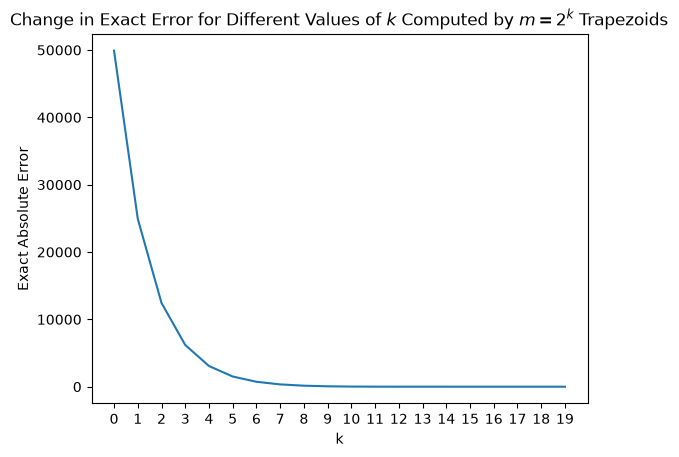

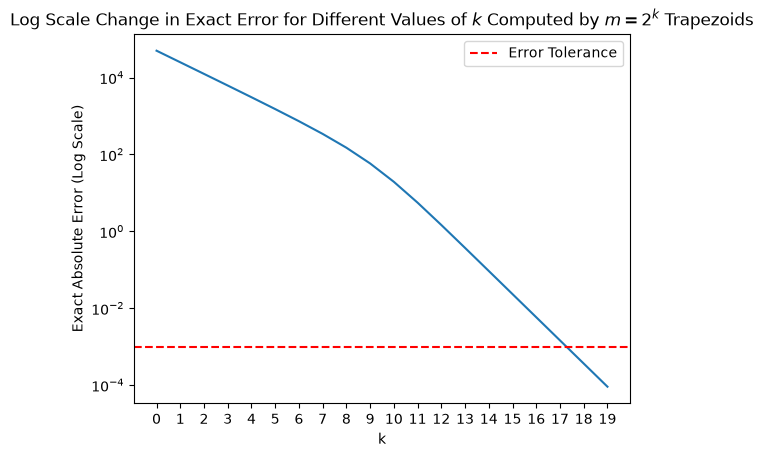

In [26]:
def composite_trapezoid_naive(f, a, b, m):
    x = a
    h = (b-a)/m
    total_sum = 0
    for _ in range(m):
        total_sum += (f(x) + f(x+h))*(h/2)
        x = x+h
    return total_sum


def experiment_a():
    a = 0.1
    b = 100
    func1 = lambda x : x**(-3)
    real_value = -0.5 * (b**(-2)-(a)**(-2)) # integral calculated analytically
    k = -1
    exact_error = np.inf
    error_tolerance = 10**(-3)
    exact_errors = []
    while exact_error > error_tolerance:
        k = k+1 # first value is 0
        m = 2**k
        approximated_integral = composite_trapezoid_naive(func1, a, b, m)
        exact_error = abs(real_value-approximated_integral)
        exact_errors.append(exact_error)
    print("Smallest value of k for which exact error is less than 0.001 is " + str(k) + " and the approximate integral is " + str(approximated_integral))

    # do one more calculation to show in the graph that error drops below
    approximated_integral = composite_trapezoid_naive(func1, a, b, 2**(k+1))
    exact_errors.append(abs(real_value-approximated_integral))
    k_values = np.arange(0, k+2, 1)
    m_values = 2**(k_values)
    plt.plot(k_values, exact_errors)
    plt.xlabel("k")
    plt.xticks(k_values)
    plt.ylabel("Exact Absolute Error")
    plt.title(r"Change in Exact Error for Different Values of $k$ Computed by $m=2^k$ Trapezoids")
    plt.show()

    # Another plot zoomed in to see convergence
    plt.plot(k_values, exact_errors)
    plt.yscale("log")
    plt.xlabel("k")
    plt.xticks(k_values)
    plt.ylabel("Exact Absolute Error (Log Scale)")
    plt.title(r"Log Scale Change in Exact Error for Different Values of $k$ Computed by $m=2^k$ Trapezoids")
    plt.axhline(1e-3, color="red", linestyle="--", label="Error Tolerance")
    plt.legend()
    plt.show()
    
    
experiment_a()

Intuitive explanation:
<br>
The function $x^{-3}$ decreases very quickly at the beginning and way more slowly for higher values of x. Trapezoid rule works best for straight lines which means it works better for higher values of x. For the interval 0.1 to 100 a large portion of x values lie at the later side when the slope changes very slowly. This means most of the error comes from the initial subintervals for which trapezoid rule was applied. It would be a better use of resources (computational steps) to use more subintervals at the beginning and less for larger values. This would lead to a faster convergence.


More mathematical explanation:
<br>
The error of one trapezoid is $T_i - I_i = \frac{h^3}{12}f''(t_i)$ for some $t_i$ where $x_i < t_i < x_{i+1}$ and for many trapezoids this becomes $E = \frac{(b-a)h^2}{12}f''(t)$ for some $t$ where $a<t<b$ since there are $m$ trapezoids and $m=\frac{b-a}{h}$. Therefore $E \propto h^2$ and $E \propto f''(t)$. For $f(x) = x^{-3}$, $f''(x) = \frac{12}{x^5}$. For small values of $x$ this is very large while the subinterval size is $h = \frac{100-0.1}{2^k}$ which is very big for small values of $k$. Since composite trapezoid rule uses equally spaced subintervals, reducing the error near $x=0.1$ where curvature is very large requires a larger 

## (b)

To improve the convergence rate of the above problem, we may use an adaptive strategy, as discussed in the book and the lecture. Consider the following formulas for approximate integration
$$I_1(f,a,b) = T(f,a,b,1)$$
$$I_2(f,a,b) = T(f,a,b,2).$$
Show, based on the precise error estimates for the trapezoid rule from the book/lecture that the error in $I_2$ can be estimated by a formula of the form 
$$E_2 = C (I_1 - I_2)$$
and determine the constant $C$ (if you can't find $C$, you may take $C = 0.5$).

## (c)
An adaptive strategy for computing the integral on an interval $[a,b]$ now is: Compute $I_2$ and $E_2$, and accept $I_2$ as an approximation when the estimated error $E_2$ is less or equal than a desired tolerance $\epsilon$.  Otherwise, apply the procedure to 
$\int_a^{\frac{b+a}{2}} f(x) \, dx$ and $\int_{\frac{b+a}{2}}^b f(x) \, dx$ with tolerances $\frac{\epsilon}{2}$.

Write a recursive python routine that implements the adaptive strategy.

Then apply this routine to the function $x^{-3}$ with $a, b, \epsilon$ as before. What is the exact error in the obtained approximation? 

## (d)

Modify the code of (c) so that the number of function evaluations is counted. Optimize your implementation such that no unnecessary function evaluations are performed.

Compare the number of function evaluations used in the adaptive strategy of (c) with the result of (a). 
(*Hint*: To count the number of function evaluations, you may use a global variable.)


## (e)
In the course of executing the recursive procedure, some subintervals are refined (split into two subintervals) while others aren't as a result of the choices made by the algorithm. It turns out that the choices made by this algorithm are not always optimal. Other algorithms, that decide in a different way which subinterval needs to be refined, may be more efficient in the sense that they require less function evaluations (while using the same formulas for the approximate integral and the approximate error associated with a subinterval).

Can you explain why this is the case? Devise an alternative, non-recursive algorithm that addresses this issue and should to lead a more efficient integral computation. Describe your approach and algorithm in about 5 to 10 sentences (bullet points).
